# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [1]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [2]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [3]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [5]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

# LabelEncoder (Codificación Entera)
# Mantiene todo en una sola columna y le asigna un número secuencial a cada categoría distinta. 
# Si tienes ["Manzana", "Pera", "Uva"], lo transforma en [0, 1, 2]

# Se utiliza casi exclusivamente para la variable objetivo (y) que el modelo intenta predecir.

In [6]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

# OneHotEncoder (Codificación Dummy)
# Elimina la columna original y crea una columna binaria nueva por cada categoría. 
# Si tienes una columna de "Color" con ["Rojo", "Verde", "Azul"], creará tres columnas distintas (es_Rojo, es_Verde, es_Azul)

# Se utiliza para variables de entrada (X) sin orden jerárquico (variables nominales)

In [7]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

La diferencia es que OneHotEncoder crea columnas para cada categoria mientras que LaberlEncoder lo mantiene en la misma columna asignando un numero secuencial a cada categoria

In [8]:
data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,sex_label,embarked_C,embarked_Q,embarked_S
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,1,False,False,True
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,0,True,False,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,0,False,False,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,0,False,False,True
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,1,False,False,True


### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

C:\Users\joaqu\AppData\Local\Temp\ipykernel_33228\350198620.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=datos_comparacion, x='sex_label', ax=axes[0], palette='pastel')
C:\Users\joaqu\AppData\Local\Temp\ipykernel_33228\350198620.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=datos_comparacion, x='sex_codificado', ax=axes[1], palette='pastel')


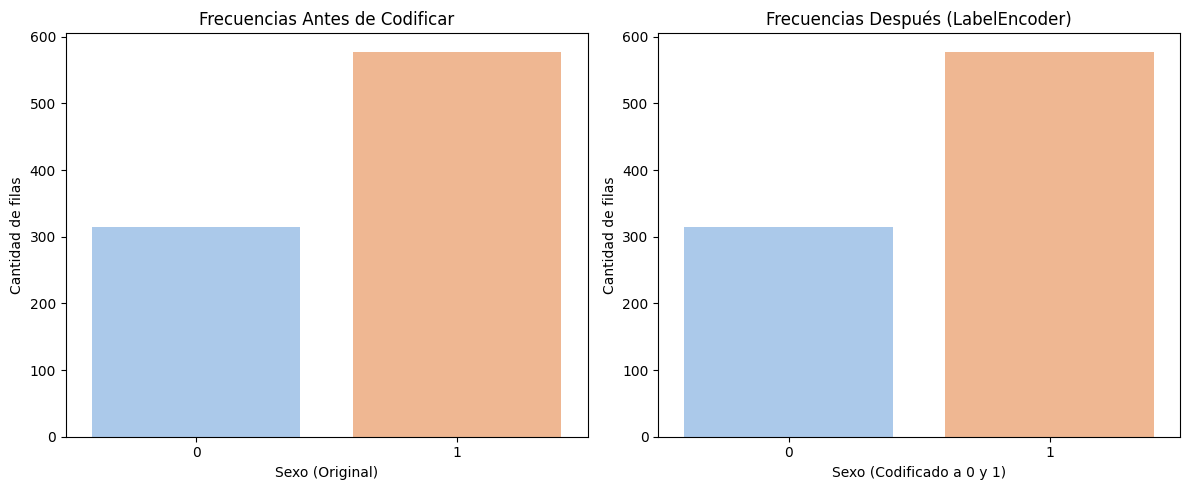

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
# 1. Hacemos una copia para no alterar tus datos originales mientras comparamos
datos_comparacion = data.copy()

# Aplicamos el LabelEncoder y guardamos el resultado en una columna NUEVA
le = LabelEncoder()
datos_comparacion['sex_codificado'] = le.fit_transform(datos_comparacion['sex_label'])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico ANTES
sns.countplot(data=datos_comparacion, x='sex_label', ax=axes[0], palette='pastel')
axes[0].set_title('Frecuencias Antes de Codificar')
axes[0].set_xlabel('Sexo (Original)')
axes[0].set_ylabel('Cantidad de filas')

# Gráfico DESPUÉS
sns.countplot(data=datos_comparacion, x='sex_codificado', ax=axes[1], palette='pastel')
axes[1].set_title('Frecuencias Después (LabelEncoder)')
axes[1].set_xlabel('Sexo (Codificado a 0 y 1)')
axes[1].set_ylabel('Cantidad de filas')

plt.tight_layout()
plt.show()


### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [12]:
onehot_encoder = pd.get_dummies(data['class'], prefix='class')

datos_ej3 = data.copy()
datos_ej3 = pd.concat([datos_ej3, onehot_encoder], axis=1)


In [ ]:
# la ventaja de OneHotEncoder es que no se pierde información, ya que cada categoría se representa en su propia columna. Esto es especialmente útil para variables nominales sin un orden jerárquico.

datos_ej3.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,...,embark_town,alive,alone,sex_label,embarked_C,embarked_Q,embarked_S,class_First,class_Second,class_Third
0,0,3,male,22.0,1,0,7.2500,S,Third,man,...,Southampton,no,False,1,False,False,True,False,False,True
1,1,1,female,38.0,1,0,71.2833,C,First,woman,...,Cherbourg,yes,False,0,True,False,False,True,False,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,...,Southampton,yes,True,0,False,False,True,False,False,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,...,Southampton,yes,False,0,False,False,True,True,False,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,...,Southampton,no,True,1,False,False,True,False,False,True


### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

Yo eligiría OneHotEncoder porque con el no perdemos información